# ERA Permutation Test

## Purpose
In this notebook, we will explore the effect of the MLB rule changes in 2023 on pitchers' ERA. For the 2023 season, there were several rules changes implemented, including the institution of a pitch clock that limited the amount of time a pitcher could take before throwing a pitch and a batter could take before being set to hit. We will perform a permutation test to evaluate the likelihood of the change in ERA that we observed under the null hypothesis.

Under the null hypothesis, we would expect that pitchers' mean ERA was not impacted by the rule change. 

## Procedure

To perform the permutation test, we will..

- Filter the pitching data to only pitchers who recorded 216 outs (8 full games worth of outs) in the season prior to the rule change and the season after the rule change.
- Calculate the ERA for the season prior to the rule change and the ERA for the season after the rule change.
- Calculate the mean difference in ERA for after rule change and before the rule change. That is the observed test statistic.
  - `average_era_delta = mean(era_after – era_before)`
- For each pitcher, shuffle the sign of the era_after - era_before
  - This simulates randomly assigning which season is before and after the rule change.
- Recalculate the test statistic and record the value.
- Repeat the previous two steps for 10,000 replicates.
- Create a histogram of the observed and simulated test statistics and find the p-value using a two-tailed test.


The data has already been cleaned and prepared for analysis. See the [Gold ERA 2022-2023 query](https://github.com/josiahpasse-cmd/baseball-pipeline/blob/main/pipeline/queries/gold/gold_era_2022_2023.sql) for details

In [0]:
import numpy as np
import pandas as pd

# Load the data from our gold table to a Pandas Dataframe
df = spark.read.table('workspace.baseball.gold_era_2022_2023').toPandas()

print(df.count())
df.sample(5)

PlayerID    110
Player      110
2022ERA     110
2023ERA     110
dtype: int64


,PlayerID,Player,2022ERA,2023ERA
35,gilbl002,"Gilbert, Logan Keith",3.199,3.729
45,hendk001,"Hendricks, Kyle Christian",4.802,3.745
93,strom001,"Stroman, Marcus Earl",3.505,3.951
29,friem001,"Fried, Max Dorian",2.477,2.549
39,grayj003,"Gray, Jonathan Charles",3.958,4.119


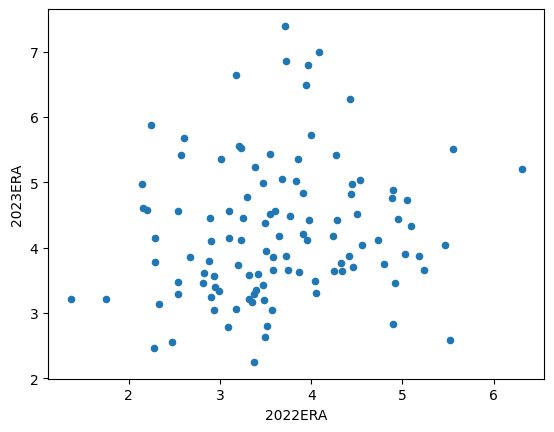

In [0]:
# Plot the points 
df.plot(kind = 'scatter', x='2022ERA', y='2023ERA');

## Discussion
Prior to analysis, the data looks reasonable. We have 110 different pitcher's records, including only those who pitches at least 216 inning in both the 2022 & 2023 season.

The ERAs range between 1 and 8 for both seasons, with a majority landing around 3.5 and 4.5 which is where I would expect the values to be.

This data appears ready for analysis.

In [0]:
# Define the test statistic
def diff_means(df: pd.DataFrame, shuffle: bool) -> float:
    # Copy the original DataFrame and calculate the per-player difference in ERA.
    # A positive number means that their ERA went up between 2023 and 2022.
    # This reflects a worse pitching performance as a low ERA means fewer runs allowed per inning.
    df_analysis = df.copy()
    df_analysis['ERA_diff'] = df_analysis['2023ERA'] - df_analysis['2022ERA']
    
    # If shuffle is true (it should be for all but the observed_value) then we
    # randomly flip the sign of the ERA_diff to simulate the null.
    if shuffle:
        df_analysis['shuffle_sign'] = np.random.choice([-1,1], size=len(df_analysis))
        df_analysis['ERA_diff'] = df_analysis['ERA_diff'] * df_analysis['shuffle_sign']
    
    # Now calculate and return the average for all players.
    return df_analysis['ERA_diff'].mean()

observed_value = diff_means(df, False)
observed_value

np.float64(0.5966999999999998)

In [0]:
# Now define the function that will run our permutation tests
def run_permutation_tests(df: pd.DataFrame, replicates: int, observed_value: float) -> list:
    results = [observed_value]

    # Loop for n replicates, calculating the mean ERA diff for each repliate.
    for _ in range(replicates-1):
        results.append(diff_means(df, True))

    return results

In [0]:
# Run the permutation test
perm_results = run_permutation_tests(df, 10000, observed_value)

perm_results[:5]

[np.float64(0.5966999999999998),
 np.float64(-0.16211818181818177),
 np.float64(-0.08682727272727274),
 np.float64(-0.27759090909090905),
 np.float64(-0.14675454545454542)]

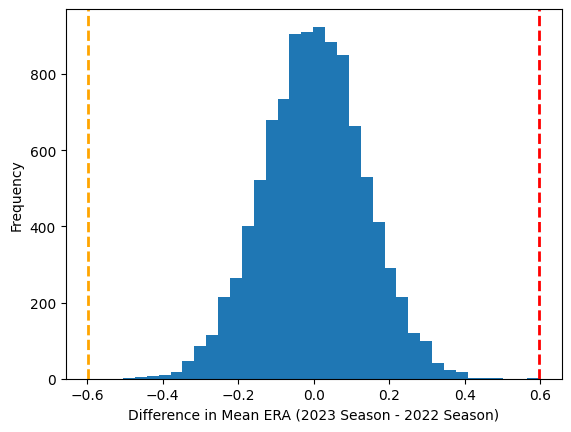

In [0]:
# Plot the results in a histogram
import matplotlib.pyplot as plt

plt.hist(perm_results, bins=35)
plt.xlabel('Difference in Mean ERA (2023 Season - 2022 Season)')
plt.ylabel('Frequency')
plt.axvline(x=observed_value, color='red', linestyle='--', linewidth=2, label='Observed Value')
plt.axvline(x=observed_value * -1, color='orange', linestyle='--', linewidth=2, label='Observed Value * -1');

In [0]:
# Calculate p-value (two-sided)
p_value = np.mean(np.abs(perm_results) >= np.abs(observed_value))
p_value

np.float64(0.0001)

## Commentary
In this permutation test, we found that results like we found are very unlikely under the null hypothesis. With a p-value of 0.0001, there is a statistically discernible difference in ERA after the 2023 season and the 2022 season, and that change resulted in ERA increasing. This means that pitchers allowed more runs in the 2023 season than in the previous season. 

We cannot say that this is due to the implementation of a pitch clock, but we can see that there is clearly a difference in ERA between these seasons that resulted in pitchers allowing more runs. Further investigation is needed to determine if other rule changes may have contributed to this change, or if there were other unconsidered factors that resulted in the increase in earned runs.